In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from ydata_profiling import ProfileReport

In [2]:
df = pd.read_csv("../datasets/Life Expectancy Data.csv")
df.head(10)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
5,Afghanistan,2010,Developing,58.8,279.0,74,0.01,79.679367,66.0,1989,...,66.0,9.20,66.0,0.1,553.328940,2883167.0,18.4,18.4,0.448,9.2
6,Afghanistan,2009,Developing,58.6,281.0,77,0.01,56.762217,63.0,2861,...,63.0,9.42,63.0,0.1,445.893298,284331.0,18.6,18.7,0.434,8.9
7,Afghanistan,2008,Developing,58.1,287.0,80,0.03,25.873925,64.0,1599,...,64.0,8.33,64.0,0.1,373.361116,2729431.0,18.8,18.9,0.433,8.7
8,Afghanistan,2007,Developing,57.5,295.0,82,0.02,10.910156,63.0,1141,...,63.0,6.73,63.0,0.1,369.835796,26616792.0,19.0,19.1,0.415,8.4
9,Afghanistan,2006,Developing,57.3,295.0,84,0.03,17.171518,64.0,1990,...,58.0,7.43,58.0,0.1,272.563770,2589345.0,19.2,19.3,0.405,8.1


In [3]:
# let's also fix and unify the spelling of column names (for my own sanity)

# Country,Year,Status,Life expectancy ,Adult Mortality,
# infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles ,
#  BMI ,under-five deaths ,Polio,Total expenditure,Diphtheria , HIV/AIDS,GDP,Population,
#  thinness  1-19 years, thinness 5-9 years,Income composition of resources,Schooling

headers = list(df.columns.values)
new_headers = []

for i in headers:
    clean_text = i.strip()

    if clean_text.isupper():
        new_headers.append(clean_text)

    else:
        new_headers.append(clean_text.title())    

    
print(new_headers)
df.columns = new_headers

['Country', 'Year', 'Status', 'Life Expectancy', 'Adult Mortality', 'Infant Deaths', 'Alcohol', 'Percentage Expenditure', 'Hepatitis B', 'Measles', 'BMI', 'Under-Five Deaths', 'Polio', 'Total Expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'Thinness  1-19 Years', 'Thinness 5-9 Years', 'Income Composition Of Resources', 'Schooling']


In [4]:
df["Country"] = df["Country"].astype('string')
df["Status"] = df["Status"].astype('string')
df.dtypes

Country                            string[python]
Year                                        int64
Status                             string[python]
Life Expectancy                           float64
Adult Mortality                           float64
Infant Deaths                               int64
Alcohol                                   float64
Percentage Expenditure                    float64
Hepatitis B                               float64
Measles                                     int64
BMI                                       float64
Under-Five Deaths                           int64
Polio                                     float64
Total Expenditure                         float64
Diphtheria                                float64
HIV/AIDS                                  float64
GDP                                       float64
Population                                float64
Thinness  1-19 Years                      float64
Thinness 5-9 Years                        float64


In [5]:
# check duplicates 
df.duplicated().sum()

np.int64(0)

In [6]:
df.shape

(2938, 22)

In [7]:
missing_row_count = df.isna().any(axis=1).sum()
missing_row_count

np.int64(1289)

In [14]:
# this just converts the value of column to 0 or 1
# Binary: Status

# change status from developing/developed to 0/1

from sklearn.preprocessing import LabelEncoder
variables = ['Status']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [ ]:
df = df.drop(['Country'],axis=1)

In [ ]:
correlation = df.corr()

<Axes: >

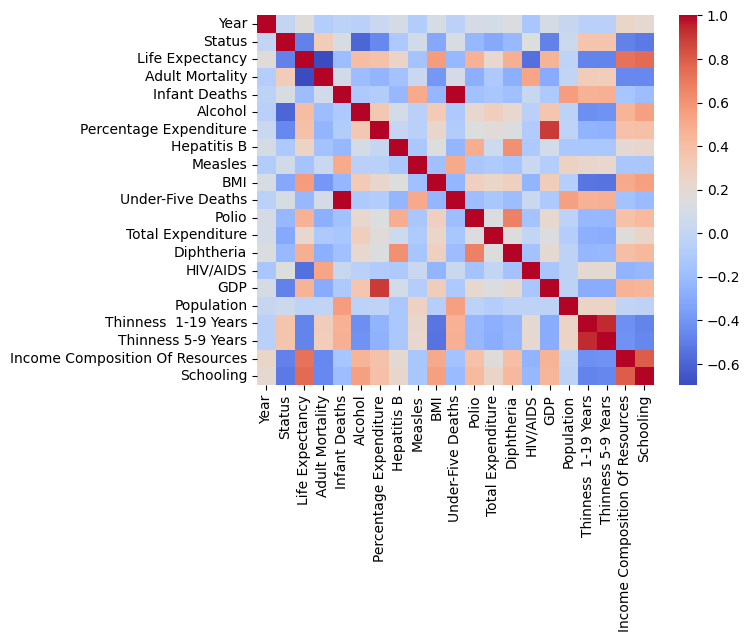

In [18]:
sns.heatmap(data=correlation, cmap='coolwarm')

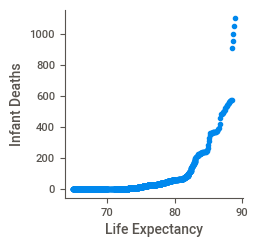

In [25]:
import seaborn as sns
from seaborn_qqplot import pplot

pplot(df, x="Life Expectancy", y="Infant Deaths", kind='qq')


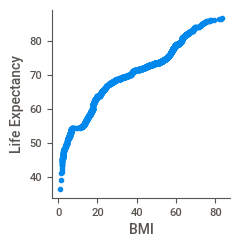

In [30]:
pplot(df, y="Life Expectancy", x="BMI", kind='qq')


In [31]:
import statsmodels.api as sm

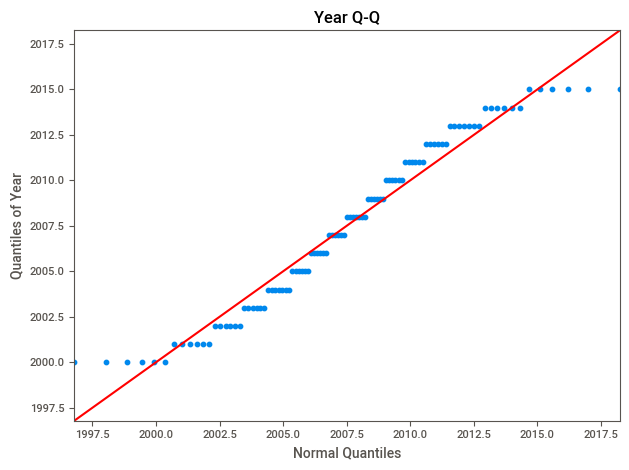

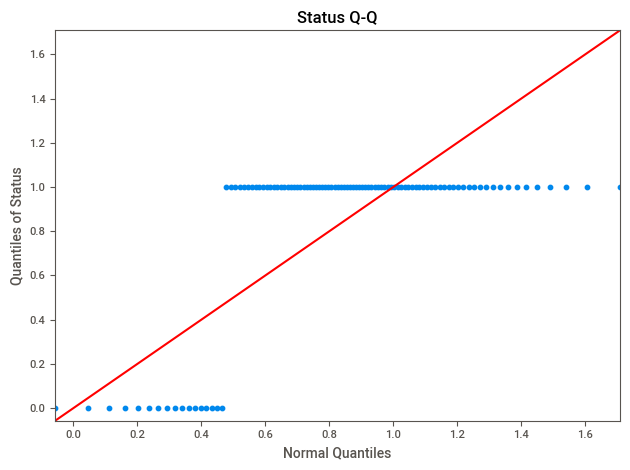

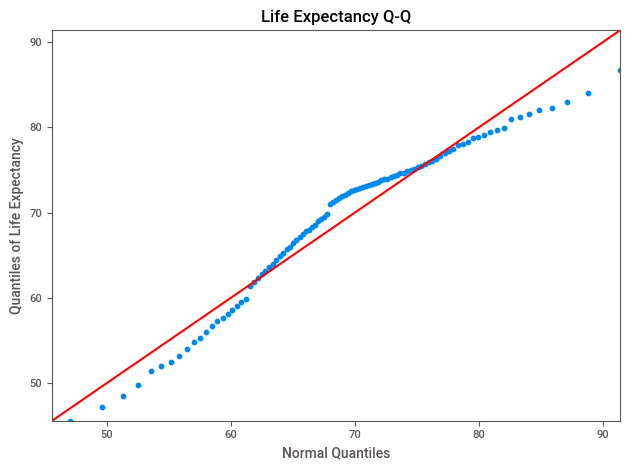

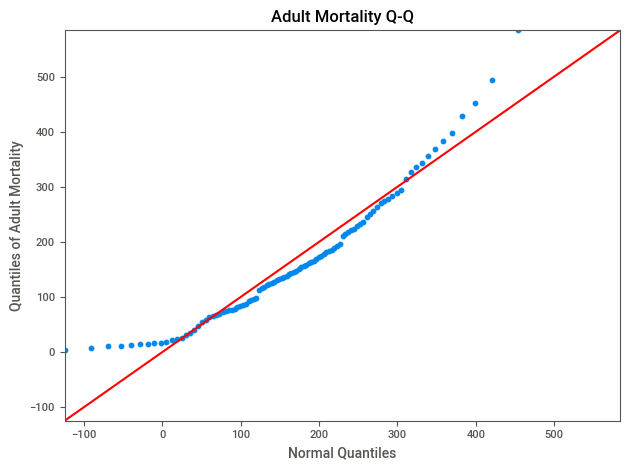

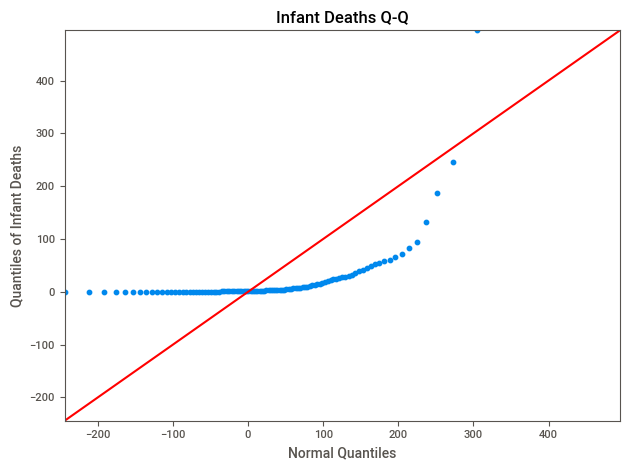

...

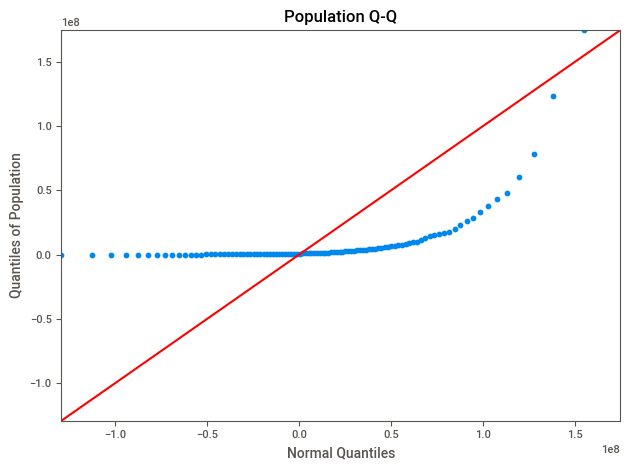

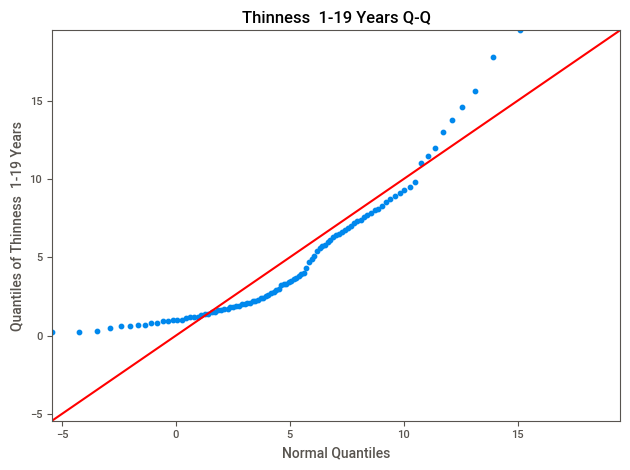

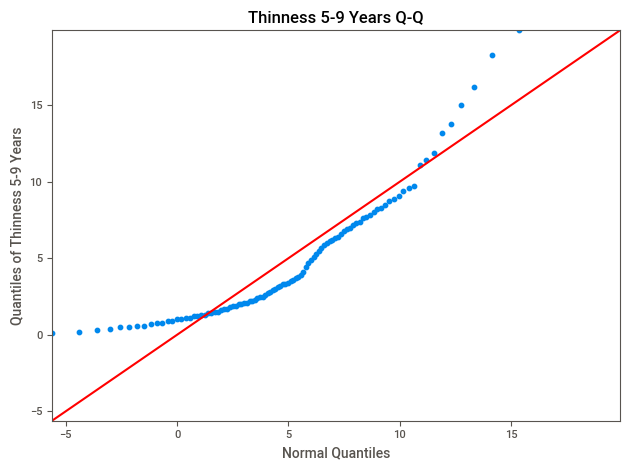

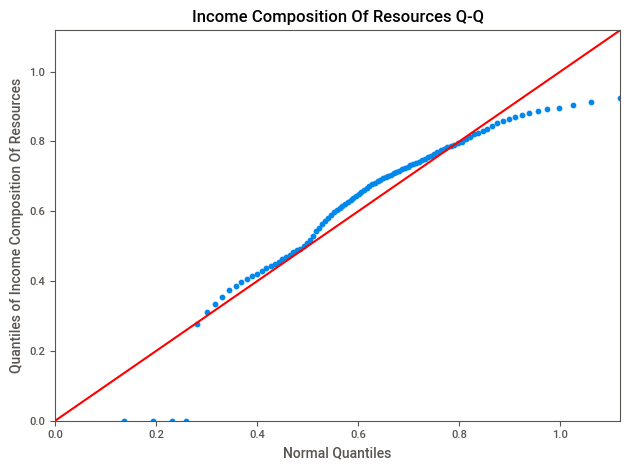

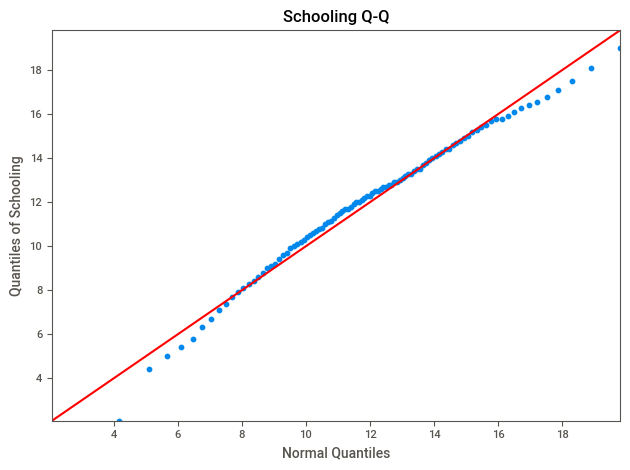

In [32]:
# This snippet displays the Q-Q plots for each numeric column!

import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

for column in df.columns:

    # Get rid of any non-numerical columns.
    if pd.api.types.is_numeric_dtype(df[column]):

        # Drop missing values in case it causes problems
        values = df[column].dropna()

        # Fit a normal distribution to THIS column's own scale.
        mean, std = values.mean(), values.std()

        # Make 99 percentiles, evenly spaced.
        probs = np.linspace(0.01, 0.99, 99)

        # Copies dataprep's method. take the sample of the quantiles.
        sample_qntls = values.quantile(probs)

        # Theoretical quantiles: what a perfectly normal distribution with
        # the datas mean and std would look like at each %
        theory_qntls = norm.ppf(probs, mean, std)

        # Combine both sets to find a shared min/max.
        vals = np.concatenate([sample_qntls, theory_qntls])
        lo, hi = vals.min(), vals.max()
        fig, ax = plt.subplots()

        # Plot sample quantiles with theoretical quantiles.
        ax.scatter(theory_qntls, sample_qntls, s=10)

        # Draw a diagonal line.
        ax.plot([lo, hi], [lo, hi], color="r")

        # Force both axes to the same range. Makes the 45 degrees fixed.
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        ax.set_title(f"{column} Q-Q")
        ax.set_xlabel("Normal Quantiles")
        ax.set_ylabel(f"Quantiles of {column}")

        plt.tight_layout()
        plt.show()

In [23]:
import sweetviz as sv

my_report = sv.analyze(df)
my_report.show_html() # Default arguments will generate to "SWEETVIZ_REPORT.html"

                                             |          | [  0%]   00:00 -> (? left)

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [7]:
profile = ProfileReport(df, title="Profiling Report")
profile.to_notebook_iframe()  # For Jupyter Notebooks
profile.to_file("exercise1_report.html")  # Save as HTML file


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 22/22 [00:00<00:00, 113638.78it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]